# 32a. Reproducción de la opción B

Este cuaderno regenera las tablas y figuras del capítulo 32 desde los archivos versionados: el registro del piloto
(`entregable3/experiments/piloto_opcion_B.json`), las corridas de NAGFuse-B (`entregable3/results/results_e2/NAGFuse-B/`),
los contrastes de la opción B (`entregable3/resultados_b/`) y la tabla maestra (`entregable3/resultados/tabla_maestra.csv`).
No reentrena ni recalcula pruebas: lee lo que produjeron `analisis_b.py` y los scripts del análisis.

In [1]:
# Configuración común. El cuaderno funciona desde docs/ (Jupyter Book) o desde la raíz del repositorio.
from pathlib import Path
import json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable3").is_dir())
RES = REPO / "entregable3" / "resultados"      # tabla maestra (incluye la fila de NAGFuse-B)
RESB = REPO / "entregable3" / "resultados_b"   # contrastes de la opción B (analisis_b.py)
RUNS = REPO / "entregable3" / "results" / "results_e2"
FIG = REPO / "docs" / "images" / "e3"
COLOR = {"NAGFuse-B": "#e67e22", "NAGFuse": "#c0392b", "ViT-B16": "#2e86c1", "RWCNet": "#27ae60", "GFN": "#8e44ad"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.precision", 4)
print("Repositorio:", REPO.name)

Repositorio: deep-learning-colaborativo


## Piloto (solo validación)

In [2]:
# Tabla 32a.1: piloto de los tres candidatos (una corrida cada uno, semilla 100) y regla de elección
P = json.load(open(REPO / "entregable3" / "experiments" / "piloto_opcion_B.json", encoding="utf-8"))
piloto = pd.DataFrame(P["filas"]).set_index("candidato")
piloto["dif_vs_A"] = piloto["f1_val"] - P["referencia_A"]
print("Referencia A (mismo intento de la búsqueda):", P["referencia_A"], "| elegido:", P["elegido"], "| se lanza:", P["lanzar"])
print("Regla:", P["regla"])
# Comprobación de la regla: mayor F1 de validación; si la diferencia con el segundo es < 0.002, gana el de menos parámetros
orden = piloto.sort_values("f1_val", ascending=False)
assert orden.index[0] == P["elegido"] and orden.f1_val.iloc[0] - orden.f1_val.iloc[1] >= 0.002
piloto

Referencia A (mismo intento de la búsqueda): 0.9688057 | elegido: NAGFuse-B2 | se lanza: True
Regla: máximo F1 de validación; empate < 0.002 -> menos parámetros; se lanza solo si supera a A


,f1_val,mejor_epoca,epocas,minutos,params_M,dif_vs_A
candidato,,,,,,
NAGFuse-B1,0.9801,23,30,6.0,76.6,0.0113
NAGFuse-B2,0.9851,21,30,6.6,52.8,0.0163
NAGFuse-B3,0.9703,8,21,2.6,113.6,0.0015


In [3]:
# El piloto no evalúa en prueba: cada carpeta de la búsqueda solo contiene predicciones de validación
for b in ["B1", "B2", "B3"]:
    d = RUNS / f"NAGFuse-{b}" / "hpo" / "trial_01"
    print(b, sorted(p.name for p in d.iterdir() if p.suffix == ".pkl"))

B1 ['config.pkl', 'env.pkl', 'history.pkl', 'model_info.pkl', 'result.pkl', 'val_predictions.pkl']
B2 ['config.pkl', 'env.pkl', 'history.pkl', 'model_info.pkl', 'result.pkl', 'val_predictions.pkl']
B3 ['config.pkl', 'env.pkl', 'history.pkl', 'model_info.pkl', 'result.pkl', 'val_predictions.pkl']


## Ejecución: hardware y tiempo por semilla

In [4]:
# Tabla 32a.2: GPU y tiempo de entrenamiento de cada semilla de NAGFuse-B.
# env.pkl guarda la versión de torch como objeto propio; este lector sustituye las clases que no estén instaladas
# por objetos vacíos, de modo que se leen los campos de texto sin necesidad de instalar torch.
class LectorSinTorch(pickle.Unpickler):
    def find_class(self, modulo, nombre):
        try:
            return super().find_class(modulo, nombre)
        except (ImportError, AttributeError):
            return type(nombre, (), {"__init__": lambda s, *a, **k: None, "__setstate__": lambda s, x: None})

def leer(p):
    with open(p, "rb") as f:
        return LectorSinTorch(f).load()

filas = []
for s in range(20):
    d = RUNS / "NAGFuse-B" / f"seed_{s:02d}"
    env, t = leer(d / "env.pkl"), leer(d / "timing.pkl")
    filas.append({"semilla": s, "GPU": env["gpu"], "inicio (UTC)": env["timestamp"],
                  "entrenamiento_min": t["train_time_s"] / 60, "latencia_lote1_ms": t["inference"]["latency_bs1_ms_mean"]})
HW = pd.DataFrame(filas).set_index("semilla")
print(HW.groupby("GPU").agg(semillas=("GPU", "size"), entrenamiento_min_min=("entrenamiento_min", "min"),
                            entrenamiento_min_max=("entrenamiento_min", "max"), latencia_ms_media=("latencia_lote1_ms", "mean")).round(1))
HW.round(1)

                       semillas  entrenamiento_min_min  entrenamiento_min_max  \
GPU                                                                             
NVIDIA A100-SXM4-80GB         3                    4.5                    9.9   
Tesla T4                     17                   12.4                   29.6   

                       latencia_ms_media  
GPU                                       
NVIDIA A100-SXM4-80GB               59.1  
Tesla T4                            58.8  


,GPU,inicio (UTC),entrenamiento_min,latencia_lote1_ms
semilla,,,,
0,NVIDIA A100-SXM4-80GB,2026-11-25 23:48:41,9.9,57.8
1,NVIDIA A100-SXM4-80GB,2026-11-26 00:03:34,4.5,59.7
2,NVIDIA A100-SXM4-80GB,2026-11-26 00:11:18,9.8,59.7
3,Tesla T4,2026-11-26 02:48:11,12.4,55.3
4,Tesla T4,2026-11-26 03:06:56,13.9,56.8
5,Tesla T4,2026-11-26 03:27:28,23.2,58.9
6,Tesla T4,2026-11-26 03:58:24,21.7,60.0
7,Tesla T4,2026-11-26 04:27:37,20.8,57.8
8,Tesla T4,2026-11-26 04:55:51,29.6,57.6


**Interpretación.** Las semillas 0 a 2 se entrenaron en A100-SXM4-80GB y las 3 a 19 en Tesla T4. El tiempo de
entrenamiento depende de la GPU; la latencia con lote de 1 casi no cambia entre las dos (de 55 a 61 ms). Las horas
están en UTC, la zona horaria de las máquinas de Colab.

## H1-B: F1 macro limpio

In [5]:
# Tabla 32a.3: los 12 contrastes de H1-B y el veredicto (alfa_B = 0.025, delta = 0.02)
H1 = pd.read_csv(RESB / "contrastes_H1_f1.csv")
RESUMEN = json.load(open(RESB / "resumen_b.json", encoding="utf-8"))
def decision(r):
    if r.supera: return "Supera (> δ)"
    if r.p_max_holm < RESUMEN["alfa_B"] and r.ic_lo > 0: return "Mejor, < δ"
    return "No significativa"
H1["decisión"] = H1.apply(decision, axis=1)
print({k: RESUMEN[k] for k in ["semillas", "alfa_B", "delta", "H1_supera_a", "H1_de", "R3_cumple", "R3_cumple_con_alfa_005", "no_supera"]})
H1[["rival", "R", "media_dif", "ic_lo", "ic_hi", "p_t_holm", "p_w_holm", "p_boot_holm", "p_max_holm", "cliff", "dz", "decisión"]]

{'semillas': 20, 'alfa_B': 0.025, 'delta': 0.02, 'H1_supera_a': 10, 'H1_de': 12, 'R3_cumple': False, 'R3_cumple_con_alfa_005': False, 'no_supera': ['ViT-B16', 'RWCNet']}


,rival,R,media_dif,ic_lo,ic_hi,p_t_holm,p_w_holm,p_boot_holm,p_max_holm,cliff,dz,decisión
0,Celik-HC,20,0.0385,0.0277,0.0507,1.7794e-07,2.2888e-05,0.0012,0.0012,1.0,1.9813,Supera (> δ)
1,MbXception,12,0.0832,0.0694,0.0994,8.5452e-09,3.4180e-03,0.0012,0.0034,1.0,5.3448,Supera (> δ)
2,ViT-B16,20,0.0115,0.0023,0.0204,2.2817e-03,3.4180e-03,0.0248,0.0248,0.6,0.8555,"Mejor, < δ"
3,GFN,20,0.0237,0.0150,0.0333,2.1009e-07,3.0518e-05,0.0012,0.0012,0.9,1.9318,Supera (> δ)
4,FocusRCNet,12,0.1399,0.1222,0.1607,6.4277e-09,3.4180e-03,0.0012,0.0034,1.0,5.5580,Supera (> δ)
5,ResMsCapsule,20,0.0421,0.0319,0.0531,1.8465e-09,2.2888e-05,0.0012,0.0012,1.0,2.7375,Supera (> δ)
6,RWCNet,20,0.0109,0.0014,0.0202,3.4762e-03,5.5809e-03,0.0248,0.0248,0.4,0.7458,"Mejor, < δ"
7,CNN,12,0.1250,0.1067,0.1455,3.0493e-08,3.4180e-03,0.0012,0.0034,1.0,4.6743,Supera (> δ)
8,MobileNetV2,12,0.1430,0.1251,0.1626,3.4931e-09,3.4180e-03,0.0012,0.0034,1.0,5.9481,Supera (> δ)
9,ResNet-18,12,0.0852,0.0674,0.1055,7.2878e-07,3.4180e-03,0.0012,0.0034,1.0,3.2235,Supera (> δ)


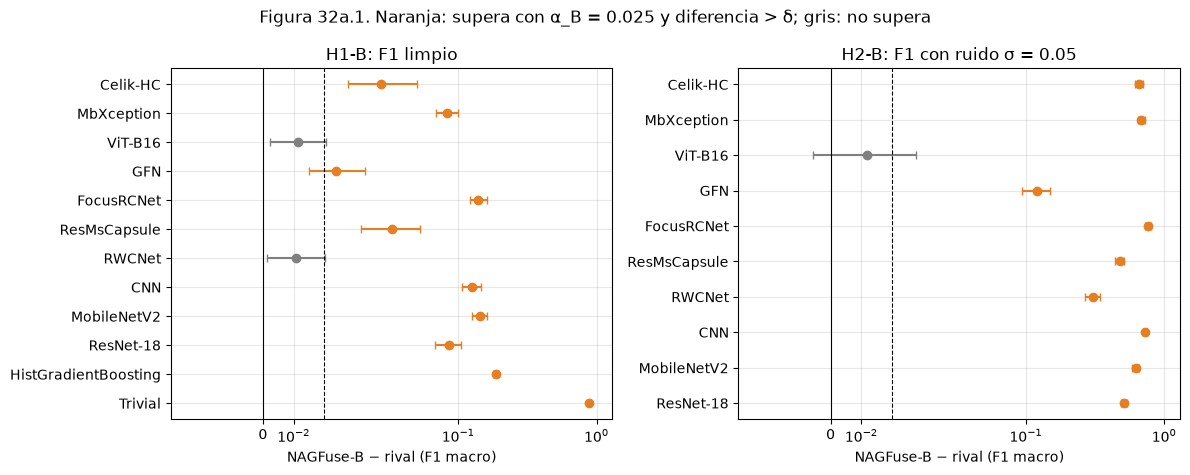

In [6]:
# Figura 32a.1 (images/e3/opcion_b_forest.png): diferencias pareadas con IC 95 % en H1 (limpio) y H2 (ruido 0.05)
H2 = pd.read_csv(RESB / "contrastes_H2_ruido005.csv")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=False)
for ax, (tab, tit) in zip(axs, [(H1, "H1-B: F1 limpio"), (H2, "H2-B: F1 con ruido σ = 0.05")]):
    t = tab.iloc[::-1]
    y = np.arange(len(t))
    for yi, (_, r) in zip(y, t.iterrows()):
        c = "#e67e22" if r.supera else "gray"
        ax.errorbar(r.media_dif, yi, xerr=[[r.media_dif - r.ic_lo], [r.ic_hi - r.media_dif]], fmt="o", color=c, capsize=3)
    ax.axvline(0, color="black", lw=0.8); ax.axvline(0.02, color="black", ls="--", lw=0.8)
    ax.set_xscale("symlog", linthresh=0.05); ax.set_xlim(-0.03, 1.3); ax.set_yticks(y, t.rival)
    ax.set_xlabel("NAGFuse-B − rival (F1 macro)"); ax.set_title(tit)
fig.suptitle("Figura 32a.1. Naranja: supera con α_B = 0.025 y diferencia > δ; gris: no supera")
plt.tight_layout()
fig.savefig(FIG / "opcion_b_forest.png", dpi=150, bbox_inches="tight")

In [7]:
# Tabla 32a.4: sensibilidad (MCC y semillas 0 a 9) y potencia observada frente a ViT-B16 y RWCNet
for f in ["contrastes_H1_mcc", "contrastes_H1_seeds0-9"]:
    t = pd.read_csv(RESB / f"{f}.csv")
    print(f, "| supera a", int(t.supera.sum()), "de", len(t), "| no supera:", list(t.rival[~t.supera]))

# Potencia de la t pareada para detectar delta al nivel alfa_B/12 con la DE pareada observada y R = 20 (simulación)
rng = np.random.default_rng(0)
for r in ["ViT-B16", "RWCNet"]:
    sd = float(H1.set_index("rival").loc[r, "de_dif"])
    x = rng.normal(0.02, sd, (200_000, 20))
    t = x.mean(1) / (x.std(1, ddof=1) / np.sqrt(20))
    print(f"{r}: sigma_d = {sd:.4f}, potencia = {(np.abs(t) > stats.t.ppf(1 - 0.025 / 12 / 2, 19)).mean():.3f}")

contrastes_H1_mcc | supera a 10 de 12 | no supera: ['ViT-B16', 'RWCNet']
contrastes_H1_seeds0-9 | supera a 10 de 12 | no supera: ['ViT-B16', 'RWCNet']
ViT-B16: sigma_d = 0.0134, potencia = 0.997


RWCNet: sigma_d = 0.0146, potencia = 0.988


**Interpretación.** NAGFuse-B supera a 10 de los 12 rivales. Frente a ViT-B16 y RWCNet la diferencia es positiva
y su IC excluye el cero, pero es menor que δ: la condición R3 no se cumple. Con la desviación pareada observada, 20
semillas bastaban para detectar una diferencia de δ con potencia cercana a 1, de modo que el resultado no se debe a
falta de semillas.

## Hipótesis secundarias y evaluación ampliada

In [8]:
# Tabla 32a.5: H3-B (no inferioridad y TOST frente al mejor rival en limpio)
pd.read_csv(RESB / "H3_no_inferioridad.csv")

,mejor_rival,R,dif,p_no_inferioridad,p_tost
0,RWCNet,20,0.0109,6.1935e-09,0.0056


,R,F1 limpio,F1 ruido 0.05,F1 ruido 0.10,F1 desenfoque,F1 oclusión,F1 fondo,ECE,NLL,F1 RealWaste,F1 Garbage v2,F1 WaRP-C
modelo,,,,,,,,,,,,
NAGFuse-B,20,0.9477,0.9034,0.8270,0.8855,0.9433,0.9404,0.0268,0.1718,0.5248,0.6039,0.3963
NAGFuse,20,0.9365,0.9036,0.8594,0.8645,0.9275,0.9198,0.0297,0.1911,0.4670,0.5227,0.3643
ViT-B16,20,0.9363,0.8915,0.8395,0.8643,0.9317,0.9158,0.0385,0.2238,0.5198,0.5862,0.4357
RWCNet,20,0.9369,0.5960,0.3430,0.8141,0.9260,0.8954,0.0296,0.1868,0.4255,0.5123,0.3316
GFN,20,0.9240,0.7833,0.5221,0.7748,0.9223,0.8961,0.0509,0.3091,0.4154,0.5253,0.2880


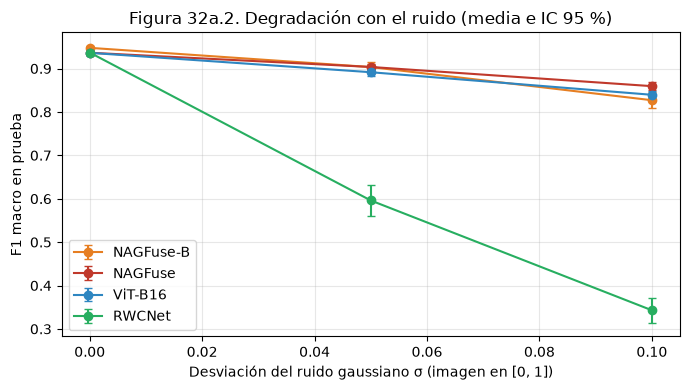

In [9]:
# Tabla 32a.6 y figura 32a.2: robustez, calibración y conjuntos adicionales (media entre semillas)
M = pd.read_csv(RES / "tabla_maestra.csv").set_index("modelo")
ESC = ["F1 limpio", "F1 ruido 0.05", "F1 ruido 0.10", "F1 desenfoque", "F1 oclusión", "F1 fondo", "ECE", "NLL",
       "F1 RealWaste", "F1 Garbage v2", "F1 WaRP-C"]
mods = ["NAGFuse-B", "NAGFuse", "ViT-B16", "RWCNet", "GFN"]
fig, ax = plt.subplots(figsize=(7, 4))
cols, x = ["F1 limpio", "F1 ruido 0.05", "F1 ruido 0.10"], [0, 0.05, 0.10]
for m in mods[:4]:
    yv = M.loc[m, cols].astype(float).values
    lo, hi = M.loc[m, [c + " IC_lo" for c in cols]].values, M.loc[m, [c + " IC_hi" for c in cols]].values
    ax.errorbar(x, yv, yerr=[yv - lo, hi - yv], marker="o", capsize=3, color=COLOR[m], label=m)
ax.set_xlabel("Desviación del ruido gaussiano σ (imagen en [0, 1])"); ax.set_ylabel("F1 macro en prueba")
ax.set_title("Figura 32a.2. Degradación con el ruido (media e IC 95 %)"); ax.legend()
plt.tight_layout()
M.loc[mods, ["R"] + ESC]

In [10]:
# Tabla 32a.7: conjuntos adicionales. Contrastes de NAGFuse-B frente a ViT-B16 y frente a A, y criterio de consistencia
EX = pd.read_csv(RESB / "contrastes_extra.csv")
print(EX[EX.rival.isin(["ViT-B16", "NAGFuse", "RWCNet"])][["ds", "rival", "R", "propio", "riv", "dif", "ic", "p_max_holm"]].round(4).to_string(index=False))
# Consistencia (protocolo, sección 5): mejor media en al menos 2 de 3 conjuntos y no significativamente peor que ningún rival
riv = EX[EX.rival != "NAGFuse"]
mejor = riv.groupby("ds").apply(lambda d: bool((d.dif > 0).all()), include_groups=False)
peor_sig = riv[(riv.dif < 0) & (riv.p_max_holm < 0.05)]
print("Mejor media por conjunto:", mejor.to_dict(), "| conjuntos con desventaja significativa:", list(peor_sig.ds))
print("Criterio de consistencia:", "se cumple" if mejor.sum() >= 2 and peor_sig.empty else "no se cumple")

       ds   rival  R  propio    riv     dif                                         ic  p_max_holm
realwaste ViT-B16 12  0.5281 0.5198  0.0083  (np.float64(-0.0116), np.float64(0.0242))      0.6592
realwaste  RWCNet 12  0.5281 0.4255  0.1026   (np.float64(0.0857), np.float64(0.1196))      0.0049
realwaste NAGFuse 20  0.5248 0.4670  0.0578   (np.float64(0.0442), np.float64(0.0697))      0.0001
    gd_v2 ViT-B16 12  0.6055 0.5862  0.0193   (np.float64(0.0103), np.float64(0.0286))      0.0293
    gd_v2  RWCNet 12  0.6055 0.5123  0.0932   (np.float64(0.0803), np.float64(0.1055))      0.0049
    gd_v2 NAGFuse 20  0.6039 0.5227  0.0812   (np.float64(0.0694), np.float64(0.0926))      0.0000
   warp_c ViT-B16 12  0.3921 0.4357 -0.0435 (np.float64(-0.0654), np.float64(-0.0189))      0.0649
   warp_c  RWCNet 12  0.3921 0.3316  0.0605   (np.float64(0.0326), np.float64(0.0897))      0.0117
   warp_c NAGFuse 20  0.3963 0.3643  0.0320    (np.float64(0.007), np.float64(0.0582))      0.1437
Mejor medi

In [11]:
# Tabla 32a.8: Friedman con Iman-Davenport y diferencia crítica de Nemenyi (11 modelos, bloques = semillas 0 a 11)
F = pd.read_csv(RESB / "friedman_nemenyi.csv").sort_values("rango_medio")
print(f"chi2 = {F.chi2.iloc[0]:.1f} | F_ID = {F.F_ID.iloc[0]:.1f} | p = {F.p.iloc[0]:.1e} | CD = {F.CD.iloc[0]:.2f}")
F["dif_con_B"] = F.rango_medio - F.set_index("modelo").loc["NAGFuse-B", "rango_medio"]
F["distinguible_de_B"] = F.dif_con_B > F.CD
F[["modelo", "rango_medio", "dif_con_B", "distinguible_de_B"]]

chi2 = 109.4 | F_ID = 113.1 | p = 4.2e-53 | CD = 4.36


,modelo,rango_medio,dif_con_B,distinguible_de_B
0,NAGFuse-B,1.7500,0.0000,False
7,RWCNet,2.3333,0.5833,False
3,ViT-B16,2.5000,0.7500,False
4,GFN,4.0000,2.2500,False
1,Celik-HC,5.0833,3.3333,False
6,ResMsCapsule,5.5000,3.7500,False
2,MbXception,7.5000,5.7500,True
10,ResNet-18,7.5000,5.7500,True
8,CNN,9.5833,7.8333,True
5,FocusRCNet,10.0000,8.2500,True


In [12]:
# Tabla 32a.9: costo y frontera de Pareto del F1 limpio frente a los GFLOPs (modelos con GFLOPs medidos)
K = pd.read_csv(REPO / "dashboard" / "data" / "costo.csv").set_index("modelo")
K["F1 limpio"] = M["F1 limpio"]
K = K.dropna(subset=["gflops"]).sort_values("gflops")
K["Pareto"] = K["F1 limpio"] >= K["F1 limpio"].cummax()      # ningún modelo con menos GFLOPs tiene mejor F1
K.assign(params_M=K.params / 1e6)[["params_M", "gflops", "lat_bs1_ms", "F1 limpio", "Pareto"]].round(4)

,params_M,gflops,lat_bs1_ms,F1 limpio,Pareto
modelo,,,,,
FocusRCNet,0.5206,0.2533,9.1637,0.8080,True
ResMsCapsule,4.2169,2.8396,4.9504,0.9056,True
Celik-HC,28.4241,6.4461,33.7622,0.9092,True
RWCNet,25.6040,9.1779,55.2718,0.9369,True
GFN,113.6713,11.3496,28.8391,0.9240,False
MbXception,28.3932,12.3896,10.1255,0.8647,False
NAGFuse-B,52.8571,18.2493,59.0459,0.9477,True
ViT-B16,85.8033,35.1261,11.4880,0.9363,False
NAGFuse,89.8185,35.8952,29.1232,0.9365,False


## Mecanismo y comparación con A (exploratorios)

In [13]:
# Tabla 32a.10: compuerta encendida frente a apagada con ruido 0.05 (mismas corridas, pi = pi0 fijo al apagarla)
MEC = pd.read_csv(RESB / "mecanismo.csv")
d = MEC.f1_ruido005_on - MEC.f1_ruido005_off
print(f"pi0 medio {MEC.pi0.mean():.3f} (de {MEC.pi0.min():.3f} a {MEC.pi0.max():.3f}); pi = 1 en el "
      f"{100 * MEC.frac_pi1_ruido005.min():.0f} % de las imágenes en todas las semillas")
print(f"F1 encendida {MEC.f1_ruido005_on.mean():.4f}, apagada {MEC.f1_ruido005_off.mean():.4f}, diferencia {d.mean():+.4f}; "
      f"positiva en {(d > 0).sum()} de {len(d)} semillas; t pareada p = {stats.ttest_rel(MEC.f1_ruido005_on, MEC.f1_ruido005_off).pvalue:.4f}; "
      f"Wilcoxon p = {stats.wilcoxon(MEC.f1_ruido005_on, MEC.f1_ruido005_off).pvalue:.4f} (sin ajuste)")

pi0 medio 0.512 (de 0.508 a 0.515); pi = 1 en el 100 % de las imágenes en todas las semillas
F1 encendida 0.9034, apagada 0.8971, diferencia +0.0063; positiva en 14 de 20 semillas; t pareada p = 0.0095; Wilcoxon p = 0.0042 (sin ajuste)


In [14]:
# Tabla 32a.11: NAGFuse-B frente a NAGFuse (A), por condición y por hardware de B
print(pd.read_csv(RESB / "B_contra_A.csv")[["cond", "R", "media_dif", "ic_lo", "ic_hi", "p_t", "p_w", "p_boot"]].round(4).to_string(index=False))
RUN = pd.read_csv(RES / "por_corrida.csv")
fb, fa = (RUN[RUN.model == m].set_index("seed").f1 for m in ["NAGFuse-B", "NAGFuse"])
dif = (fb - fa).to_frame("B − A").join(HW["GPU"])
dif.groupby("GPU")["B − A"].agg(["size", "mean"]).join(fb.to_frame("F1 B").join(HW["GPU"]).groupby("GPU").mean()).round(4)

      cond  R  media_dif   ic_lo  ic_hi    p_t    p_w  p_boot
    limpio 20     0.0113  0.0021 0.0205 0.0032 0.0027  0.0162
ruido_0.05 20    -0.0002 -0.0153 0.0138 0.9683 0.9854  0.9618


,size,mean,F1 B
GPU,,,
NVIDIA A100-SXM4-80GB,3,0.0040,0.9414
Tesla T4,17,0.0126,0.9488


**Interpretación.** Con ruido la compuerta se abre del todo en todas las imágenes, como garantiza el Teorema 2, y
apagarla reduce el F1 en 0.006, menos que δ. La ventaja de B sobre A en limpio (+0.011) es mayor en las semillas
entrenadas en T4 que en las tres entrenadas en A100; con tres semillas no se puede separar el efecto del hardware del
de las ramas.